# Counterfactual regret minimization on a game tree

This notebook implements the game-tree CFR pseudocode in the
[lecture notes](../../learning_efg.typ), then applies it to Kuhn poker.
Each round computes continuation values, combines histories into counterfactual
utilities, and updates one regret minimizer per information set.

| Symbol | Description | Python representation |
|:------:|:------------|:----------------------|
| $h$, $ha$ | A history and its child after action $a$ | `GameNode`, `h.children[a]` |
| $z$, $u_i(z)$ | A terminal history and player $i$'s payoff | `z.payoff[i]` |
| $j$, $A_j$ | An information set and its legal actions | `InformationSet`, `j.actions` |
| $h\in j$ | Histories indistinguishable to the acting player | `game.histories[j]` |
| $b_j^{(t)}$ | Current local action distribution at $j$ | `strategies[j]` |
| $p(a\mid h)$ | Chance or opponent action probability | `game.action_probabilities(h, strategies)[a]` |
| $V(h)$ | Continuation payoff from $h$, without reach to $h$ | `V[h]` |
| $\pi_i(h)$ | Product of player $i$'s earlier action probabilities | `own_reach[h]` |
| $\pi_{-i}(h)$ | Product of chance and opponents' earlier action probabilities | `external_reach[h]` |
| $g_j^{(t)}$ | Counterfactual action utilities, summed over $h\in j$ | `utilities[j]` |
| $R_j$, $C_j$ | Local regret minimizer and cumulative regrets | `local_learners[j]`, `regret_sum` |

### One CFR round on the game tree

**Input:** the game tree, terminal utilities $u_i(z)$, and a fixed profile of
current local strategies $b_j^{(t)}$ for all players.

**Step 1: Compute continuation values bottom-up.**

- At a terminal history $z$, set $V(z)=u_i(z)$.
- At a chance or opponent node, set $V(h)=\sum_a p(a\mid h)V(ha)$.
- At player $i$'s node in information set $j$, set
  $V(h)=\sum_{a\in A_j}b_j^{(t)}[a]V(ha)$.

$V(h)$ evaluates play from $h$ onward, even if the current strategies never
reach it. It excludes the probability of reaching $h$.

**Step 2: Compute counterfactual utilities.**

Start with external reach $\pi_{-i}=1$ at the root. Multiply by $p(a\mid h)$
along chance and opponent edges; carry the weight unchanged along player $i$'s
edges. For every information set $j$ and action $a$, compute

$$
g_j^{(t)}[a]=\sum_{h\in j}\pi_{-i}(h)V(ha).
$$

Sum all histories in the information set without normalizing their reach
weights. Exclude player $i$'s own earlier action probabilities, so even an
information set with zero own reach can receive a regret update.

**Step 3: Update regrets and strategies.**

$$
U_j=\sum_a b_j^{(t)}[a]g_j^{(t)}[a],\qquad
r_j^{(t)}[a]=g_j^{(t)}[a]-U_j,\qquad
C_j[a]\leftarrow C_j[a]+r_j^{(t)}[a].
$$

Pass the instantaneous regrets $r_j^{(t)}$ to `R_j.ObserveRegret`. Regret matching
chooses the next distribution proportional to $\max(C_j[a],0)$, or uniformly if
all positive parts are zero. Both players finish their updates against the same
saved strategies before either calls `NextStrategy` again.

In [1]:
from dataclasses import dataclass, field
from itertools import permutations, product
import numpy as np

### Data structures

`InformationSet(player, actions)` represents what the acting player knows.
Players are numbered from zero; actions are ordered labels. Put display context,
such as the player's own card and public betting history, in `metadata`.
All histories in one information set share the same object and action distribution.

`GameNode` represents one complete history:

- A player node has an `information_set` and one `children[a]` per legal action.
  Its owner is `information_set.player`.
- A chance node has no information set and supplies `chance_probabilities` for
  its children.
- A terminal node has a tuple `payoff`, with one entry per player, and no children.

Use distinct nodes for distinct histories. Supply a finite, perfect-recall tree
with no cycles, normalized chance probabilities, and consistent actions within
each information set. `GameTree(root)` gathers the histories belonging to each
information set and records top-down and bottom-up traversal orders. Dataclasses
use `eq=False` so each information set and node is a distinct dictionary key.

Local strategies are NumPy arrays in `j.actions` order. The tree operations map
directly to the pseudocode:

- `continuation_values(player, strategies)` implements Step 1.
- `reach_probabilities(player, strategies)` separates own and external reach.
- `counterfactual_utilities(player, V, external_reach)` sums histories in Step 2.

Own reach is used only to average strategies; counterfactual utilities use
external reach. Chance and opponent probabilities are applied explicitly on
the game tree.

In [2]:
@dataclass(eq=False)
class InformationSet:
    player: int
    actions: tuple
    metadata: dict = field(default_factory=dict)


@dataclass(eq=False)
class GameNode:
    information_set: InformationSet | None = None
    children: dict = field(default_factory=dict)
    chance_probabilities: dict = field(default_factory=dict)
    payoff: tuple | None = None


class GameTree:
    def __init__(self, root: GameNode):
        self.root = root
        self.top_down = []
        self.histories = {}

        def visit(h):
            self.top_down.append(h)
            if h.information_set is not None:
                self.histories.setdefault(h.information_set, []).append(h)
            for child in h.children.values():
                visit(child)

        visit(root)
        self.bottom_up = self.top_down[::-1]
        self.information_sets = list(self.histories)

    def action_probabilities(self, h: GameNode, strategies: dict) -> dict:
        j = h.information_set
        if j is None:
            return h.chance_probabilities
        return dict(zip(j.actions, strategies[j]))

    def continuation_values(self, player: int, strategies: dict) -> dict:
        """Step 1: expected payoffs from each history, excluding reach to it."""
        V = {}
        for h in self.bottom_up:
            if h.payoff is not None:
                V[h] = h.payoff[player]
            else:
                probabilities = self.action_probabilities(h, strategies)
                V[h] = sum(probabilities[a] * V[child] for a, child in h.children.items())
        return V

    def reach_probabilities(self, player: int, strategies: dict):
        """Separate the player's own reach from chance and opponents' reach."""
        own_reach, external_reach = {self.root: 1.0}, {self.root: 1.0}
        for h in self.top_down:
            if h.payoff is not None:
                continue
            probabilities = self.action_probabilities(h, strategies)
            own_move = h.information_set is not None and h.information_set.player == player
            for a, child in h.children.items():
                own_reach[child] = own_reach[h] * (probabilities[a] if own_move else 1)
                external_reach[child] = external_reach[h] * (1 if own_move else probabilities[a])
        return own_reach, external_reach

    def counterfactual_utilities(self, player: int, V: dict, external_reach: dict) -> dict:
        """Step 2: combine all histories in each of this player's information sets."""
        utilities = {}
        for j, histories in self.histories.items():
            if j.player != player:
                continue
            utilities[j] = np.array([
                sum(external_reach[h] * V[h.children[a]] for h in histories)
                for a in j.actions
            ])
        return utilities

In [3]:
class RegretMatching:
    """A local regret minimizer receiving instantaneous action regrets."""

    def __init__(self, num_actions: int):
        self.regret_sum = np.zeros(num_actions)

    def NextStrategy(self) -> np.ndarray:
        positive_regrets = np.maximum(self.regret_sum, 0)
        total = positive_regrets.sum()
        if total > 0:
            return positive_regrets / total
        return np.full(len(self.regret_sum), 1 / len(self.regret_sum))

    def ObserveRegret(self, regret: np.ndarray) -> None:
        self.regret_sum += regret


class CFR:
    """One game-tree CFR learner for a player, with one local learner per information set."""

    def __init__(self, game: GameTree, player: int):
        self.game = game
        self.player = player
        self.local_learners = {
            j: RegretMatching(len(j.actions)) for j in game.information_sets if j.player == player
        }
        self.local_strategies = {}
        self.strategy_sum = {j: np.zeros(len(j.actions)) for j in self.local_learners}

    def NextStrategy(self) -> dict:
        """Save the local distributions used throughout this round."""
        self.local_strategies = {
            j: learner.NextStrategy() for j, learner in self.local_learners.items()
        }
        return self.local_strategies

    def ObserveUtility(self, opponent_strategies: dict) -> None:
        strategies = {**opponent_strategies, **self.local_strategies}
        # Steps 1 and 2: continuation values, external reach, counterfactual utilities.
        V = self.game.continuation_values(self.player, strategies)
        own_reach, external_reach = self.game.reach_probabilities(self.player, strategies)
        utilities = self.game.counterfactual_utilities(self.player, V, external_reach)
        for j, learner in self.local_learners.items():
            b = self.local_strategies[j]
            # Step 3: subtract the current strategy's utility, then accumulate regrets.
            U = b @ utilities[j]
            learner.ObserveRegret(utilities[j] - U)
            # Perfect recall gives all histories in j the same own reach. Count j once.
            h = self.game.histories[j][0]
            self.strategy_sum[j] += own_reach[h] * b

    def AverageStrategy(self) -> dict:
        """Return the own-reach-weighted average at each information set."""
        return {
            j: weights / weights.sum() if weights.sum() > 0 else
               np.full(len(j.actions), 1 / len(j.actions))
            for j, weights in self.strategy_sum.items()
        }

### Kuhn poker: information sets and terminal payoffs

Each player antes one chip and privately receives one of `J < Q < K`, without
replacement. Player 1 can check or bet one chip; after a check, Player 2 can check
or bet. Facing a bet, a player can fold or call. A fold or an unbet showdown is
worth one net chip to the winner; a called bet is worth two.

We construct one game tree directly. The chance root has six equally likely
ordered deals. Each deal leads to a tree of public actions and terminal payoffs.
Information sets are keyed by `(player, own_card, public_history)`, so histories
with different opponent cards share a local strategy. There are six information
sets per player, each containing two histories.

`build_hand` uses both cards to compute terminal payoffs, but selects the acting
player's information set using only their own card and the public history.

In [4]:
cards = ('J', 'Q', 'K')
opening_actions = ('check', 'bet')
responses = ('fold', 'call')
information_sets = {}

for player, histories in enumerate([((), ('check', 'bet')), (('check',), ('bet',))]):
    for card in cards:
        for history in histories:
            actions = opening_actions if history in ((), ('check',)) else responses
            information_sets[player, card, history] = InformationSet(
                player, actions, metadata={'card': card, 'history': history}
            )


def build_hand(card1, card2, history=()):
    win = 1 if cards.index(card1) > cards.index(card2) else -1
    if history and history[-1] == 'fold':
        folding_player = (len(history) - 1) % 2
        value = -1 if folding_player == 0 else 1
        return GameNode(payoff=(value, -value))
    if history == ('check', 'check') or (history and history[-1] == 'call'):
        value = win * (2 if history[-1] == 'call' else 1)
        return GameNode(payoff=(value, -value))

    player = len(history) % 2
    own_card = (card1, card2)[player]
    j = information_sets[player, own_card, history]
    return GameNode(information_set=j, children={
        a: build_hand(card1, card2, history + (a,)) for a in j.actions
    })


deals = list(permutations(cards, 2))
kuhn = GameTree(GameNode(
    children={deal: build_hand(*deal) for deal in deals},
    chance_probabilities={deal: 1 / len(deals) for deal in deals},
))

### Averaging and measuring convergence

The average local strategy weights each round by the player's **own reach**:

$$
\bar b_j[a]=\frac{\sum_t\pi_i^{(t)}(j)b_j^{(t)}[a]}
                    {\sum_t\pi_i^{(t)}(j)}.
$$

Perfect recall makes own reach identical at all histories in $j$. `ObserveUtility`
accumulates this weight once per information set; `AverageStrategy` normalizes
it. An unweighted average of local distributions would be incorrect. If an
information set has zero total own reach, any distribution is valid there;
we return uniform. Chance and opponent reach are excluded from this average.

For Kuhn poker, an exact best response is small enough to enumerate: each player
has $2^6=64$ pure strategies. Each strategy chooses one action per information
set, shared by all its histories. Maximizing independently at each history would
incorrectly let the player use the opponent's hidden card.

Let $u_i(b_1,b_2)$ be the root value computed from the game tree. For the averaged
strategies, define

$$
L=-\max_{b_2}u_2(\bar b_1,b_2),\qquad
U=\max_{b_1}u_1(b_1,\bar b_2),\qquad
\text{exploitability}=\frac{U-L}{2}.
$$

Kuhn poker is zero-sum, so $L$ and $U$ bracket its equilibrium value. The average
profile's payoff alone is not an equilibrium certificate. Enumeration is useful
for this small game; the number of pure strategies grows exponentially.

Each iteration evaluates all deals and updates both learners against the same
saved profile. `ObserveUtility` changes regrets but keeps the current local
strategies fixed until the next `NextStrategy` call.

In [5]:
def best_response_value(game: GameTree, player: int, opponent_strategies: dict) -> float:
    """Exact best response for a small game, with one action per information set."""
    infosets = [j for j in game.information_sets if j.player == player]
    best = -np.inf
    for choices in product(*(range(len(j.actions)) for j in infosets)):
        response = {j: np.eye(len(j.actions))[a] for j, a in zip(infosets, choices)}
        V = game.continuation_values(player, {**opponent_strategies, **response})
        best = max(best, V[game.root])
    return best


iterations = 50_000

In [6]:
cfr1, cfr2 = CFR(kuhn, 0), CFR(kuhn, 1)
checkpoints = set(np.geomspace(1, iterations, 160).astype(int))
history = []

for t in range(1, iterations + 1):
    b1, b2 = cfr1.NextStrategy(), cfr2.NextStrategy()
    cfr1.ObserveUtility(b2)
    cfr2.ObserveUtility(b1)

    if t in checkpoints:
        average1, average2 = cfr1.AverageStrategy(), cfr2.AverageStrategy()
        lower = -best_response_value(kuhn, 1, average1)
        upper = best_response_value(kuhn, 0, average2)
        V = kuhn.continuation_values(0, {**average1, **average2})
        history.append((t, V[kuhn.root], lower, upper))

history = np.array(history)
t, value, lower, upper = history[-1]
print(f"{int(t):,} CFR iterations; {len(kuhn.information_sets)} information sets")
print(f"Average profile payoff to Player 1: {value:.6f} chips/hand")
print(f"Best-response bounds: [{lower:.6f}, {upper:.6f}]")
print(f"Exploitability: {(upper - lower) / 2:.6f} chips/hand")

50,000 CFR iterations; 12 information sets
Average profile payoff to Player 1: -0.055556 chips/hand
Best-response bounds: [-0.056573, -0.054575]
Exploitability: 0.000999 chips/hand


### Convergence graphs

The left plot measures how much either player can gain by deviating. The right
plot shows the averaged profile's payoff and its best-response bounds approaching
$-1/18$ chips per hand, the equilibrium value used in
[OpenSpiel's Kuhn poker checks](https://github.com/google-deepmind/open_spiel/blob/master/open_spiel/python/algorithms/cfr_test.py).

The plotted strategies are averages over all iterations up to each checkpoint.
The current strategy need not converge, and the curves need not be monotone.
The cell saves PNG and PDF copies in the notebook's working directory.

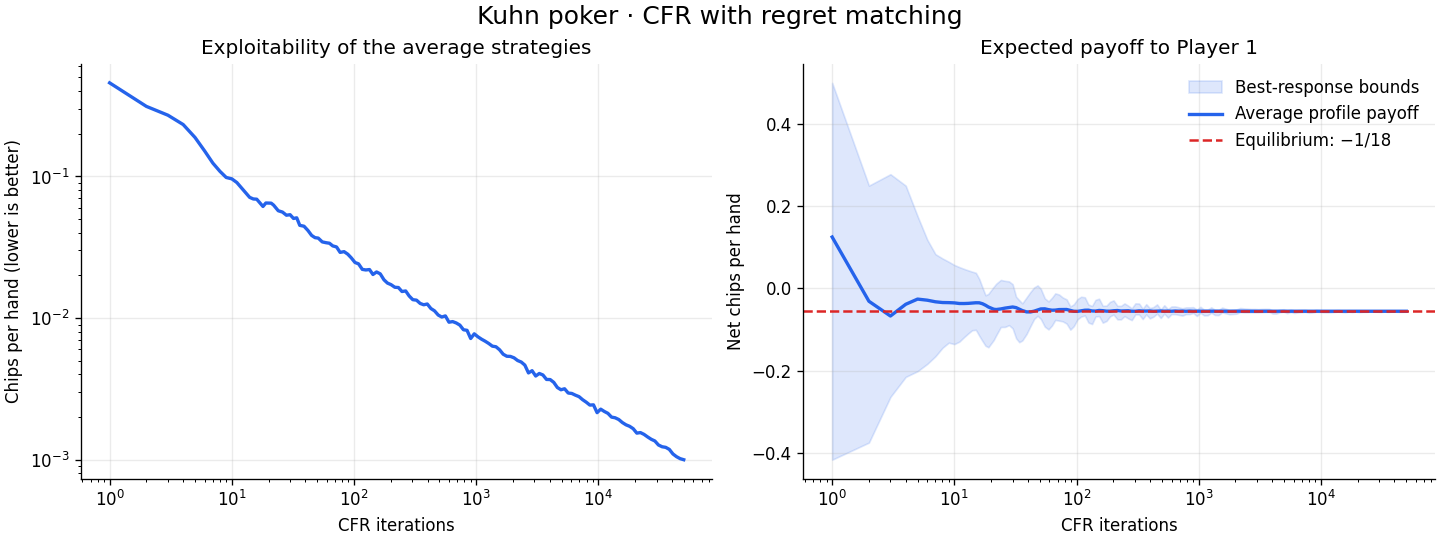

In [7]:
import matplotlib.pyplot as plt

steps, values, lower, upper = history.T
exploitability = (upper - lower) / 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')

axes[0].loglog(steps, exploitability, color='#2563eb', linewidth=2)
axes[0].set_title('Exploitability of the average strategies')
axes[0].set_ylabel('Chips per hand (lower is better)')

axes[1].fill_between(steps, lower, upper, color='#2563eb', alpha=0.15,
                     label='Best-response bounds')
axes[1].semilogx(steps, values, color='#2563eb', linewidth=2,
                 label='Average profile payoff')
axes[1].axhline(-1 / 18, color='#dc2626', linestyle='--', label='Equilibrium: −1/18')
axes[1].set_title('Expected payoff to Player 1')
axes[1].set_ylabel('Net chips per hand')
axes[1].legend(frameon=False)

for ax in axes:
    ax.set_xlabel('CFR iterations')
    ax.grid(True, which='major', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Kuhn poker · CFR with regret matching', fontsize=15)
fig.savefig('kuhn_convergence.png', dpi=180)
fig.savefig('kuhn_convergence.pdf')
plt.show()

### Inspecting the learned strategy

`AverageStrategy` already returns a conditional action distribution at each
information set. Every information set in this example has positive average own
reach because the first iteration plays uniformly. Kuhn poker has multiple
optimal strategies for Player 1, so exploitability is a more useful convergence
check than matching a particular table of action probabilities.

In [8]:
for player, average in enumerate([average1, average2]):
    print(f"\nPlayer {player + 1}")
    for j, probabilities in average.items():
        context = ' → '.join(j.metadata['history']) or 'start'
        actions = ', '.join(f"{a}: {p:.3f}" for a, p in zip(j.actions, probabilities))
        print(f"  {j.metadata['card']} | {context:12} | {actions}")


Player 1
  J | start        | check: 0.793, bet: 0.207
  J | check → bet  | fold: 1.000, call: 0.000
  Q | start        | check: 1.000, bet: 0.000
  Q | check → bet  | fold: 0.454, call: 0.546
  K | start        | check: 0.379, bet: 0.621
  K | check → bet  | fold: 0.000, call: 1.000

Player 2
  Q | check        | check: 1.000, bet: 0.000
  Q | bet          | fold: 0.662, call: 0.338
  K | check        | check: 0.000, bet: 1.000
  K | bet          | fold: 0.000, call: 1.000
  J | check        | check: 0.667, bet: 0.333
  J | bet          | fold: 1.000, call: 0.000
